In [1]:
import re
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

In [4]:
# for mac devices
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")


print("Is MPS built into PyTorch?:", torch.backends.mps.is_built())
print("Is MPS available on this Mac?:", torch.backends.mps.is_available())

Using device: mps
Is MPS built into PyTorch?: True
Is MPS available on this Mac?: True


In [5]:
corpus = """
    I love machine learning.
    I love deep learning.
    Machine learning is interesting.
    Deep learning is powerful.
    Machine learning uses data.
    Deep learning uses neural networks.
    """

In [7]:
def tokenize(text):

    text = text.lower()

    text = re.sub(r"[^a-zA-Z\s]", "", text)
    return text.split()

In [8]:
tokens = tokenize(corpus)
tokens[:10]

['i',
 'love',
 'machine',
 'learning',
 'i',
 'love',
 'deep',
 'learning',
 'machine',
 'learning']

In [9]:
vocab = sorted(set(tokens))
len(vocab)

12

In [10]:
word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}

for word, idx in word_to_id.items():
    print(f"{word}: {idx}")

data: 0
deep: 1
i: 2
interesting: 3
is: 4
learning: 5
love: 6
machine: 7
networks: 8
neural: 9
powerful: 10
uses: 11


In [11]:
encoded_tokens = [word_to_id[word] for word in tokens]
encoded_tokens

[2, 6, 7, 5, 2, 6, 1, 5, 7, 5, 4, 3, 1, 5, 4, 10, 7, 5, 11, 0, 1, 5, 11, 9, 8]

In [13]:
window_size = 2
def create_skipgram_pairs(tokens, window_size=2):
    pairs = []

    for i, target in enumerate(tokens):
        start = max(0, i-window_size)
        end = min(len(tokens), i+window_size+1)

        for j in range(start, end):
            if i==j:
                continue

            context = tokens[j]
            pairs.append((target, context))

    return pairs

In [14]:
pairs = create_skipgram_pairs(encoded_tokens, window_size=2)

In [15]:
class SkipGramDataset(Dataset):

    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        traget, context = self.pairs[index]
        return (torch.tensor(traget, dtype=torch.long), torch.tensor(context, dtype=torch.long))

In [16]:
dataset = SkipGramDataset(pairs)
dataloader = DataLoader(dataset, batch_size=4, shuffle=False)
len(dataloader)

24

In [17]:
encoded_tokens

[2, 6, 7, 5, 2, 6, 1, 5, 7, 5, 4, 3, 1, 5, 4, 10, 7, 5, 11, 0, 1, 5, 11, 9, 8]

In [18]:
class SkipGram(nn.Module):

    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.linear = nn.Linear(embedding_dim, vocab_size)

    def forward(self, traget):
        embedding = self.embedding(traget)
        output = self.linear(embedding)
        return output

In [19]:
embedding_dim = 50
vocab_size = len(dataset)

model = SkipGram(vocab_size=vocab_size, embedding_dim=embedding_dim).to(device)

In [20]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [21]:
epochs = 100

loss_history = []

for epoch in range(epochs):

    total_loss = 0

    for target, context in dataloader:

        target = target.to(device)
        context = context.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        output = model(target)

        # Calculate loss
        loss = criterion(
            output,
            context
        )

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        total_loss += loss.item()

    average_loss = (
        total_loss /
        len(dataloader)
    )

    loss_history.append(
        average_loss
    )

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch {epoch + 1:03d} | "
            f"Loss: {average_loss:.4f}"
        )

Epoch 010 | Loss: 1.8847
Epoch 020 | Loss: 1.8439
Epoch 030 | Loss: 1.8323
Epoch 040 | Loss: 1.8234
Epoch 050 | Loss: 1.8129
Epoch 060 | Loss: 1.8065
Epoch 070 | Loss: 1.7993
Epoch 080 | Loss: 1.7951
Epoch 090 | Loss: 1.7948
Epoch 100 | Loss: 1.7941


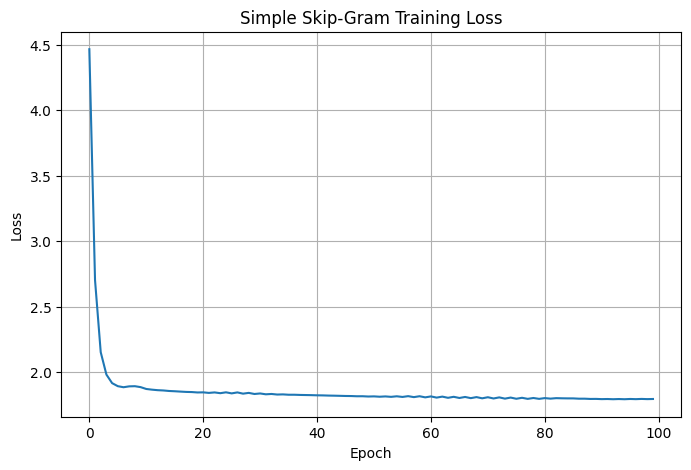

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    loss_history
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Simple Skip-Gram Training Loss"
)

plt.grid()

plt.show()

In [23]:
model.embedding.weight

Parameter containing:
tensor([[-1.8018, -2.0553, -0.0517,  ...,  1.6507,  0.3012,  0.1992],
        [ 0.0935,  0.4425,  0.0968,  ...,  0.2789,  0.9460, -0.5976],
        [-0.3190,  1.3402, -2.2730,  ...,  1.6272, -1.6287, -0.7768],
        ...,
        [-0.4917, -0.7070, -1.0775,  ...,  0.7056,  1.5541, -0.3607],
        [ 0.4646, -1.5230,  1.2753,  ..., -0.3004, -0.4606, -1.7292],
        [ 0.1148,  2.0239,  1.0336,  ..., -0.1759, -0.7247, -0.5257]],
       device='mps:0', requires_grad=True)

In [25]:
embeddings = (
    model.embedding.weight
    .detach()
    .cpu()
)

print(
    "Embedding shape:",
    embeddings.shape
)

Embedding shape: torch.Size([94, 50])


In [28]:
word = "machine"

word_id = word_to_id[word]

vector = embeddings[word_id]

print("Word:", word)
print("ID:", word_id)

print("\nVector:")
print(vector)

print(
    "\nVector shape:",
    vector.shape
)

Word: machine
ID: 7

Vector:
tensor([-8.8333e-01, -4.6702e-01, -1.2917e+00, -3.9955e-01,  2.3711e-01,
        -1.6741e-02, -7.0804e-01,  7.3700e-01, -1.6330e+00, -2.4118e-01,
         8.6044e-03, -2.1147e-01,  2.4259e-01,  5.3805e-01,  8.9017e-01,
        -2.5979e+00, -7.1709e-01, -1.3610e+00, -4.1012e-01,  5.2814e-02,
        -1.3864e-02,  6.1303e-04,  5.0051e-01, -7.3528e-01, -3.7562e-01,
        -3.7624e-02,  5.1193e-01,  3.2499e-01, -5.7508e-01,  2.0445e-01,
         9.1675e-01, -1.4310e+00,  6.6795e-02,  2.7000e-01,  5.6906e-01,
         3.4180e-02, -8.0170e-01,  6.8590e-02,  5.6534e-02, -1.1305e+00,
         4.7923e-02, -5.1111e-01,  1.1310e-02,  1.3922e+00,  1.3157e+00,
         2.9916e-01,  5.1871e-01, -9.8782e-01,  9.2726e-01, -6.4363e-01])

Vector shape: torch.Size([50])
